<a href="https://colab.research.google.com/github/huzaifamachinelearning/Virexo-internship/blob/main/Virexo_task_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
url='https://raw.githubusercontent.com/huzaifamachinelearning/credit-card-clustering/main/credit_card_data.csv'
cc_data=pd.read_csv(url)
cc_data.head(5)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [ ]:
cc_explore=cc_data.copy()

In [ ]:
cc_explore.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [ ]:
cc_explore.drop('CUST_ID',axis=1,inplace=True)

##imputing  credit_limits and minimum_payments
the distributions are right-tailed so used median

In [ ]:
import matplotlib.pyplot as plt
def plot_histogram(df, column, bins=100):
    plt.figure(figsize=(10, 6))

    df[column].hist(bins=bins)

    plt.title(f'Distribution of {column.replace("_", " ").title()}', fontsize=16)
    plt.xlabel(column.replace("_", " ").title(), fontsize=13)
    plt.ylabel('Number of Customers', fontsize=13)

    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

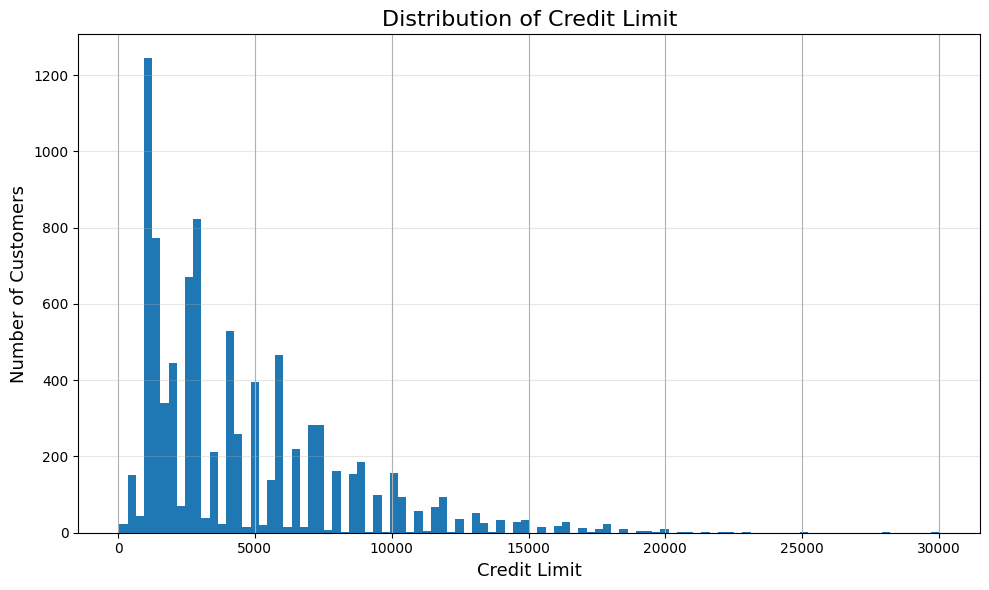

In [ ]:

plot_histogram(cc_explore,'CREDIT_LIMIT')

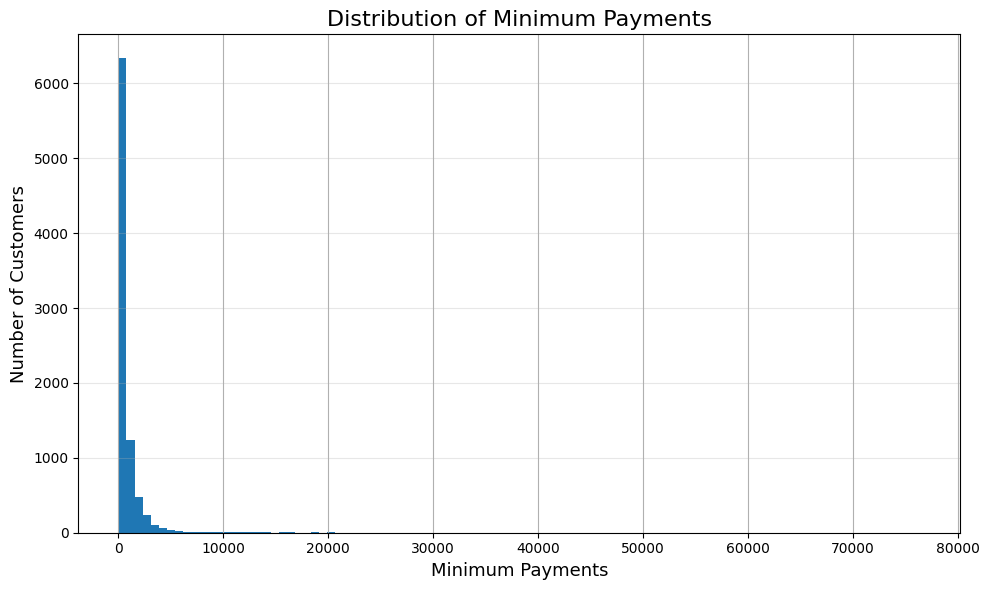

In [ ]:
plot_histogram(cc_explore,'MINIMUM_PAYMENTS')

check if log transofrming the data makes it better

---




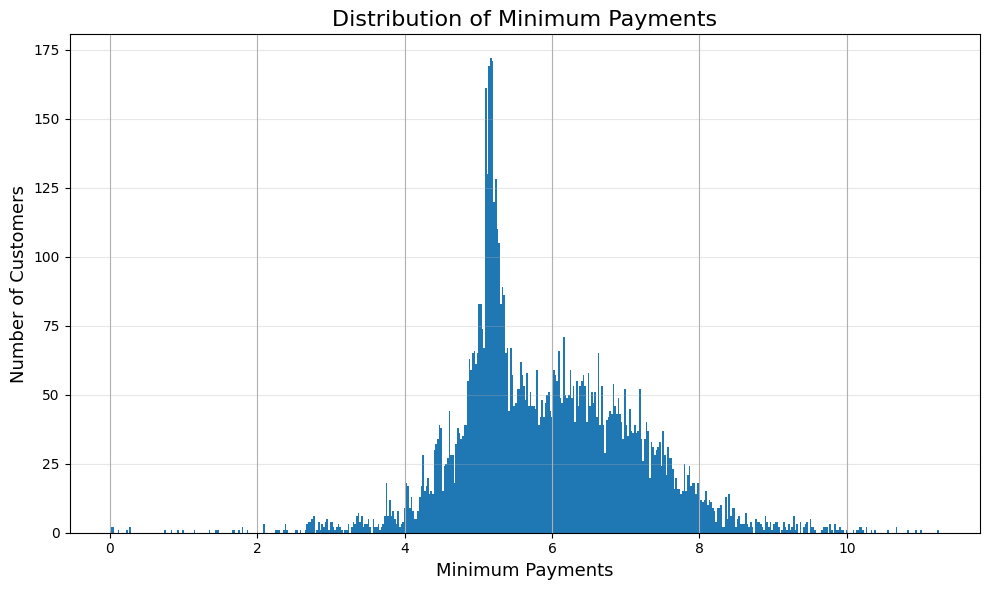

In [ ]:

import numpy as np

plt.figure(figsize=(10, 6))

np.log1p(cc_explore['MINIMUM_PAYMENTS']).hist(bins=500)

plt.title('Distribution of Minimum Payments', fontsize=16)
plt.xlabel('Minimum Payments', fontsize=13)
plt.ylabel('Number of Customers', fontsize=13)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.show()

In [ ]:
credit_limit_median=cc_explore['CREDIT_LIMIT'].median()
min_payments_median=cc_explore['MINIMUM_PAYMENTS'].median()
cc_explore['CREDIT_LIMIT']=cc_explore['CREDIT_LIMIT'].fillna(credit_limit_median)
cc_explore['MINIMUM_PAYMENTS']=cc_explore['MINIMUM_PAYMENTS'].fillna(credit_limit_median)


we see that many columns have zero as thier first quaritle and some even have zero as thier median

In [ ]:
cc_explore.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.282473,1733.143852,938.899654,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.646702,2895.063757,2363.389034,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,170.857654,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,335.628312,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,931.596638,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


many of the features are right tailed

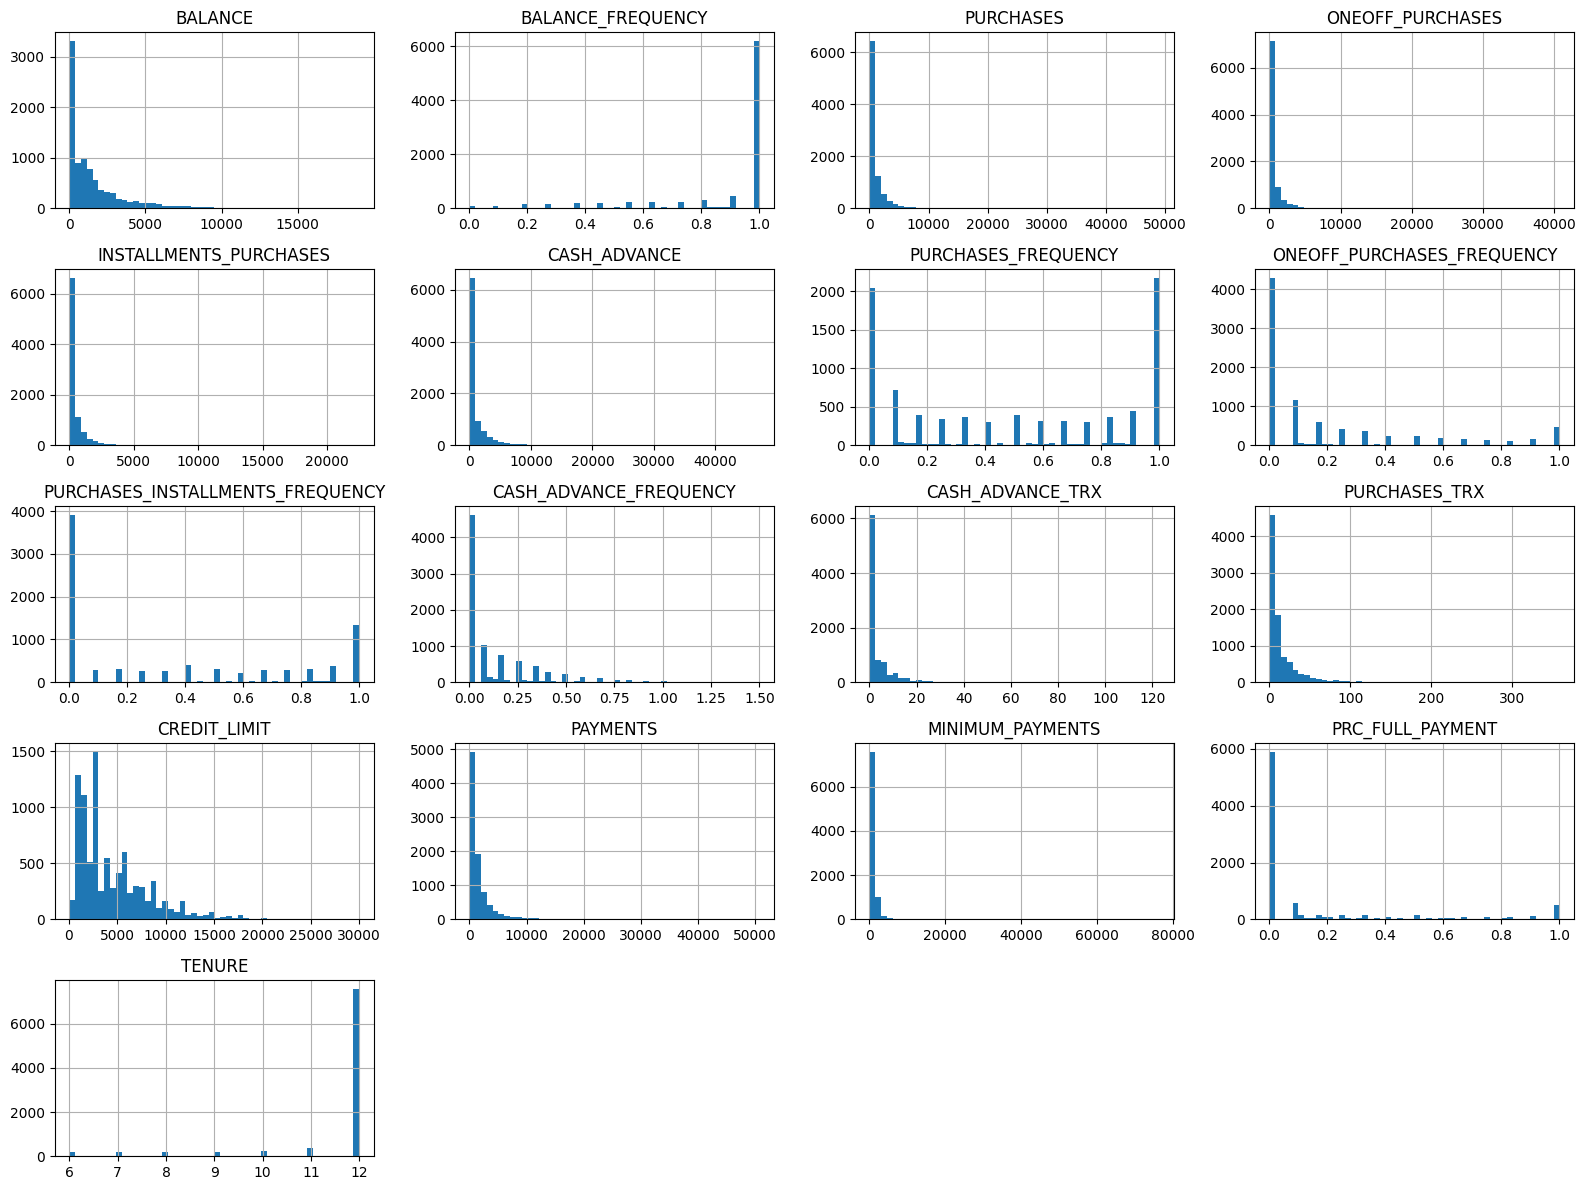

In [ ]:
import matplotlib.pyplot as plt

cc_explore.hist(
    bins=50,
    figsize=(16, 12)
)

plt.tight_layout()
plt.show()

checking if log makes things better

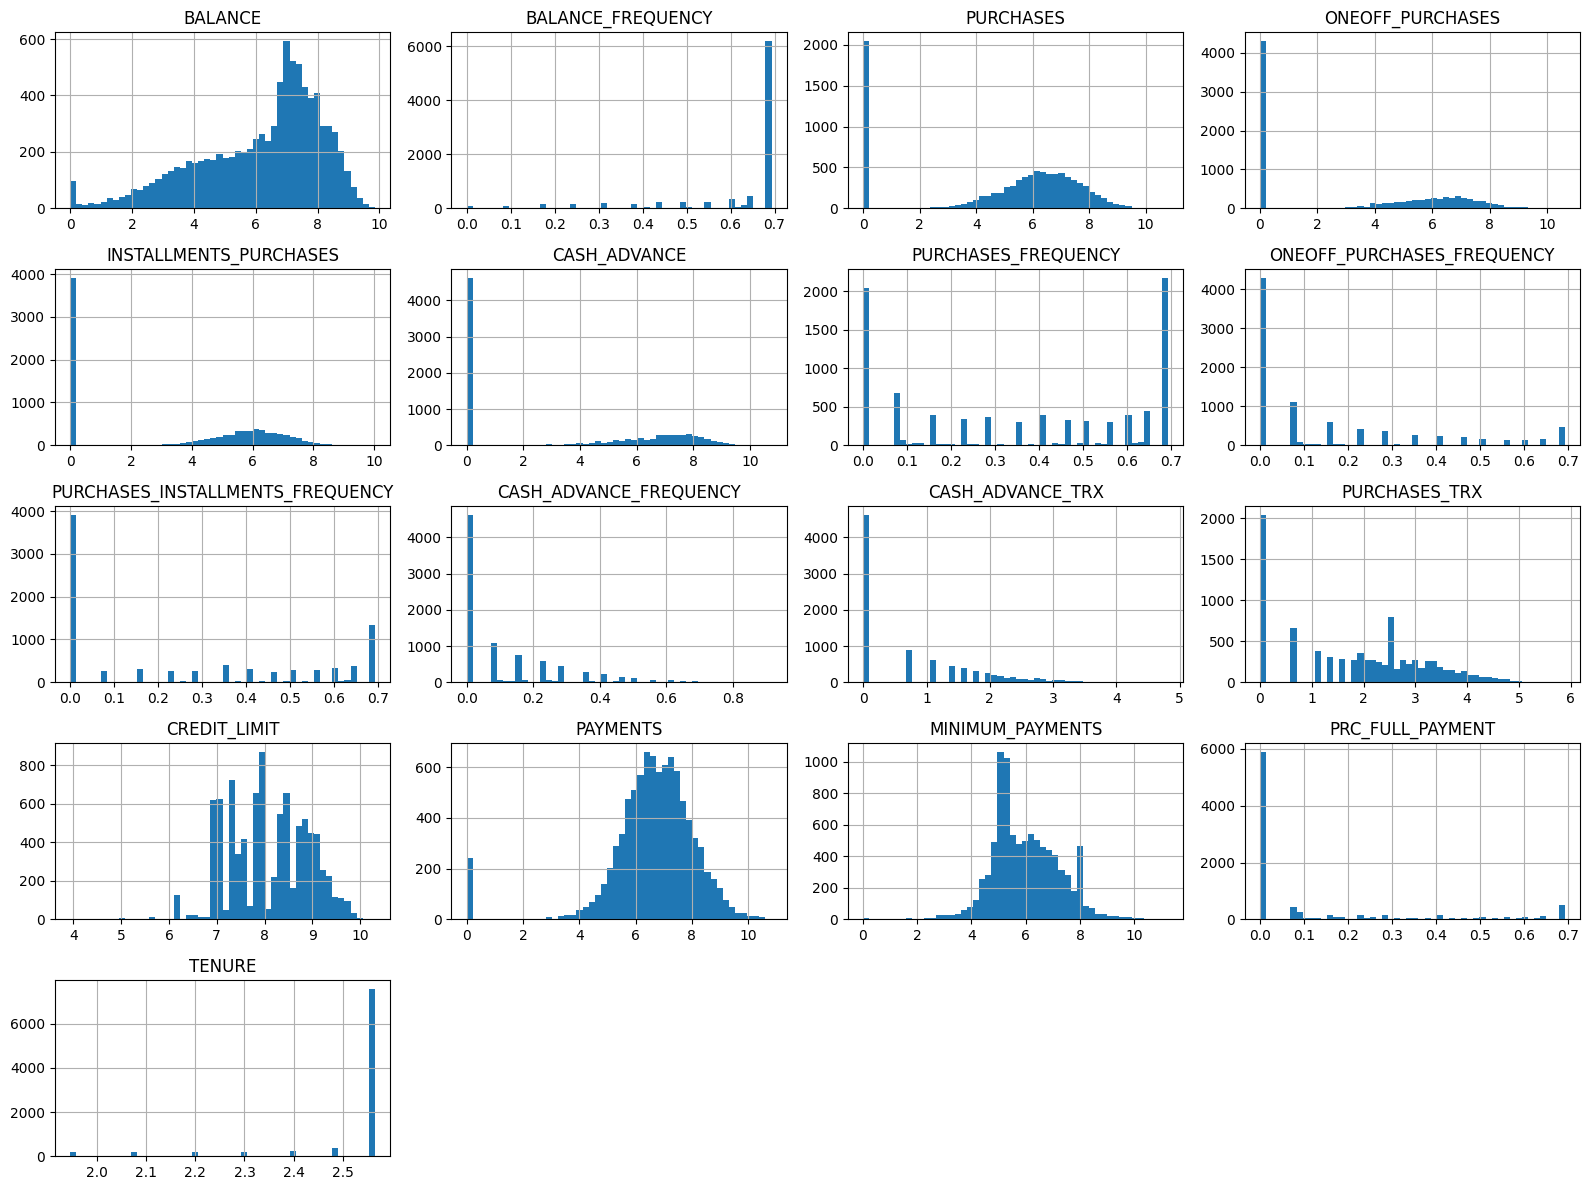

In [ ]:
import matplotlib.pyplot as plt

np.log1p(cc_explore).hist(
    bins=50,
    figsize=(16, 12)
)

plt.tight_layout()
plt.show()

most of the customers have been a credit card holder for 12 months

In [ ]:
cc_explore['TENURE'].value_counts(normalize=True)

,proportion
TENURE,
12,0.847374
11,0.040782
10,0.026369
6,0.022793
8,0.021899
7,0.021229
9,0.019553


## PURCHASES and CASH_ADVANCE

The origin of zeros in these columns and thier related columns (ONEOFF_PURCHASES,INSTALLMENT_PURCHASES,CASH_ADVANCE_TRX, PURCHASES_TRX)
can be understood by the following facts:
1. 51 percent of people only make purchases and take no cash in advance
2. 22% of people only take cash in advance and not make purchases.

These facts account for large number of zeros in CASH_ADVANCE and PURCHASES.
INSTALLMENT_PURCHASES and ONEOFF_PURCHASES bear the burden of zeros from the previous facts plus the fact that Of those who make purchases (77% of people) 27% only do one off and 32% only do installments

The zeros in CASH_ADVANCE and PURCHASES almost account for zeros in CASH_ADVANCE_TRX and PURCHASES_TRX

Similarly the zeros in many of the frequencies may also be due to this



The most frequent number of transactions is 1. In purchase_trx it is closely followed by 12

In [ ]:
cc_explore['CASH_ADVANCE'].value_counts(normalize=True)

,proportion
CASH_ADVANCE,
0.000000,0.517095
197.915586,0.000112
1430.485333,0.000112
211.485981,0.000112
364.489187,0.000112
...,...
101.183886,0.000112
496.939698,0.000112
1204.068667,0.000112


In [ ]:
purchase_cash=cc_explore.copy()
purchase_cash['taken_cash']=purchase_cash['CASH_ADVANCE']>0
purchase_cash['made_purchase']=purchase_cash['PURCHASES']>0
pd.crosstab(purchase_cash['made_purchase'],purchase_cash['taken_cash'],normalize='all')

taken_cash,False,True
made_purchase,,
False,0.000112,0.228268
True,0.516983,0.254637


In [ ]:
purchases=cc_explore[cc_explore['PURCHASES']>0].copy()
purchases['made_installments']=purchases['INSTALLMENTS_PURCHASES']>0
purchases['made_oneoff_purchases']=purchases['ONEOFF_PURCHASES']>0
print(pd.crosstab(purchases['made_installments'],purchases['made_oneoff_purchases'],normalize='all'))
print(len(purchases)/len(cc_explore))



made_oneoff_purchases     False     True 
made_installments                        
False                  0.000000  0.271358
True                   0.326962  0.401680
0.7716201117318435


In [ ]:
(cc_explore['PURCHASES_TRX'].astype(bool) ^ cc_explore['PURCHASES'].astype(bool)).sum()

np.int64(6)

In [ ]:
(cc_explore['CASH_ADVANCE_TRX'].astype(bool) ^ cc_explore['CASH_ADVANCE'].astype(bool)).sum()

np.int64(0)

In [ ]:
cc_explore[cc_explore['PURCHASES_TRX']>0]['PURCHASES_TRX'].value_counts(normalize=True)

,proportion
PURCHASES_TRX,
1,0.096583
12,0.082537
2,0.054880
6,0.050970
3,0.045468
...,...
309,0.000145
224,0.000145
133,0.000145


## Credit card usage
69% of the people use their creditcard to the highest degree of frequency
remaining 31% are thinly spread among lower frequencies and bank can introduce perks to intice the remaining inactive customers


In [ ]:
cc_explore['BALANCE_FREQUENCY'].value_counts(normalize=True)

,proportion
BALANCE_FREQUENCY,
1.000000,0.693966
0.909091,0.045810
0.818182,0.031061
0.727273,0.024916
0.545455,0.024469
0.636364,0.023352
0.454545,0.019218
0.363636,0.018994
0.272727,0.016872


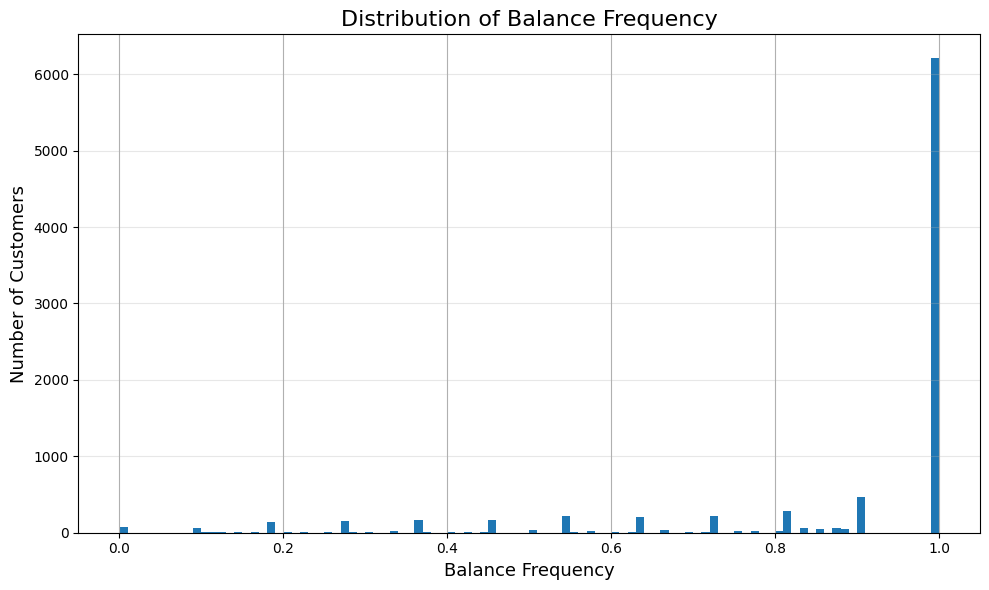

In [ ]:
plot_histogram(cc_explore,'BALANCE_FREQUENCY')

## more than 65% of people do not pay full payment ever

In [ ]:
(cc_explore['PAYMENTS']==0).sum()

np.int64(240)

In [ ]:
cc_explore['PRC_FULL_PAYMENT'].value_counts(normalize=True)

,proportion
PRC_FULL_PAYMENT,
0.000000,0.659553
1.000000,0.054525
0.083333,0.047598
0.166667,0.018547
0.250000,0.017430
0.500000,0.017430
0.090909,0.017095
0.333333,0.014972
0.100000,0.010503


1. With PURCHASES going up ONEOFF_PURCHASES go up reliably (0.92) and rougly 70% of the increase in purchases is due to ONEOFF_PURCHASES. THe customers consistently make ONEOFF_PURCHASES


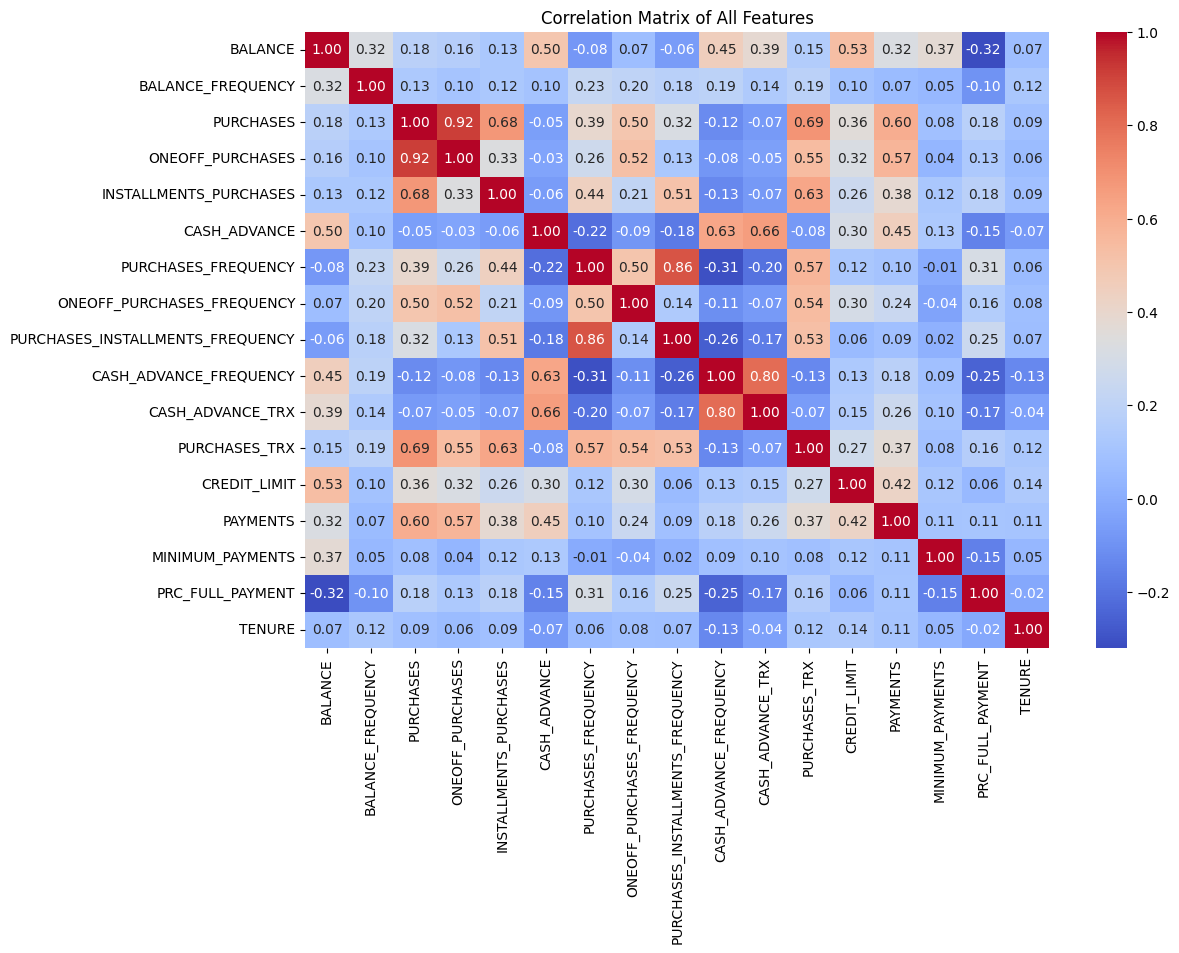

In [ ]:
import seaborn as sns
all_correlations=cc_explore.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(all_correlations, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of All Features')
plt.show()


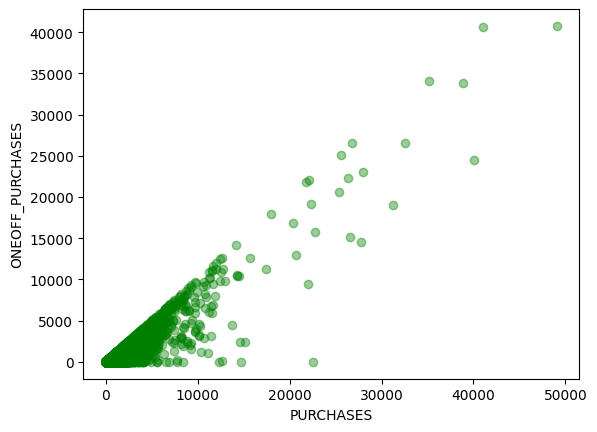

In [ ]:
plt.scatter(x=cc_explore['PURCHASES'],y=cc_explore['ONEOFF_PURCHASES'],c='g',alpha=0.4)
plt.xlabel('PURCHASES')
plt.ylabel('ONEOFF_PURCHASES')
plt.show()

In [ ]:
m,b=np.polyfit(cc_explore['PURCHASES'],cc_explore['ONEOFF_PURCHASES'],1)
print(f' m:{m}')
print(f' b:{b}')


 m:0.7122692273341492
 b:-122.1145606791352


##PCA plotting (before running kmeans)
1. The functions plot_kmeans_clusters_2d and its 3D version is used to plot pca version of the high dimensional space in which kmeans operates(after the log transformation and standard scaling)
2. First, original data(after log transform and standard scaling) is plotted using pca before running any kmean to recognize cluster ourselves.
3. Then the same thing is repeated with the enhanced dataset

In [ ]:
from sklearn.base import clone
from matplotlib.colors import BoundaryNorm

def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'b.',alpha=0.3, markersize=1)


def plot_kmeans_clusters_2d(data,labels, centroids, ):


    pca=PCA(n_components=2)
    X=pca.fit_transform(data)
    centroids_2d=pca.transform(centroids)
    # Plotting
    plt.figure(figsize=(10, 8))
    norm = BoundaryNorm(
    range(11),
    ncolors=10
    )

    plt.scatter(X[:,0],X[:,1],c=labels, cmap='tab10',norm=norm,
                        s=10, alpha=0.4, edgecolors='none',marker='o')


    # Plot centroids
    plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1],
                marker='o', s=35, linewidths=8,
                c=list(range(len(centroids))), cmap='tab10',norm=norm, zorder=10, alpha=0.9)
    plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1],
                marker='x', s=2, linewidths=12,
                color='red', zorder=11, alpha=1)


    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')

    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:


from matplotlib.animation import FuncAnimation
from sklearn.decomposition import PCA


plt.rcParams['animation.embed_limit'] = 200  # MB, so jshtml doesn't get truncated


def anim_kmeans_clusters_3d(data,labels=None,centroids=None):
    pca=PCA(n_components=3)
    transformed_data_3d=pca.fit_transform(data)
    if centroids is not None:
      centroids_3d=pca.transform(centroids)
    fig = plt.figure(figsize=(15, 12))
    ax = fig.add_subplot(111, projection='3d')

    x, y, z = transformed_data_3d[:, 0], transformed_data_3d[:, 1], transformed_data_3d[:, 2]
    norm = BoundaryNorm(
    range(11),
    ncolors=10
    )


    if labels is not None:
        sc = ax.scatter(x, y, z, c=labels, cmap='tab10',
                        s=30, alpha=0.3, edgecolors='none',norm=norm, depthshade=True,marker='s')
    else:
        sc = ax.scatter(x, y, z, s=30, alpha=0.3, edgecolors='none',color='green', depthshade=True)
    if centroids is not None:
      cmap=plt.get_cmap('tab10')
      sc = ax.scatter(
          centroids[:, 0],
          centroids[:, 1],
          centroids[:, 2],
          marker='o',
          s=250,
          facecolors='none',
          edgecolors=cmap(range(len(centroids))),
          linewidths=3,
          alpha=1
      )

      # X markers
      sc=ax.scatter(
          centroids[:, 0],
          centroids[:, 1],
          centroids[:, 2],
          marker='x',
          s=200,
          color='red',
          linewidths=5,
          zorder=11
      )

    # ---- labels & title ----
    ax.set_xlabel('Principal Component 1', labelpad=12, fontsize=11)
    ax.set_ylabel('Principal Component 2', labelpad=12, fontsize=11)
    ax.set_zlabel('Principal Component 3', labelpad=12, fontsize=11)
    ax.set_title('3D PCA of Credit Card Data', fontsize=16, pad=20, fontweight='bold')

    # ---- remove the grid entirely ----
    ax.grid(False)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.set_visible(False)      # remove background panes
        axis._axinfo['grid']['linewidth'] = 0  # kill grid lines
    ax.set_axis_off()
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=25, azim=45)






    # ---- full 360° rotation ----
    def rotate(angle):
        ax.view_init(elev=25, azim=angle)
        return (sc,)

    anim = FuncAnimation(
        fig, rotate,
        frames=np.arange(0, 360, 2),
        interval=40, blit=False, repeat=True
    )

    plt.close(fig)
    return anim




In [ ]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline,Pipeline
preprocessor=make_pipeline(
     FunctionTransformer(func=np.log1p,inverse_func=np.expm1),
    StandardScaler(),
)

In [ ]:
import matplotlib
matplotlib.rc('animation', html='jshtml')



There seem to be atleast two clusters that stand out but we must be cautious in our conslusion because the first three pca components only explain 64% of the variance

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from IPython.display import HTML


animation=anim_kmeans_clusters_3d(preprocessor.fit_transform(cc_explore))
HTML(animation.to_jshtml())

In [ ]:
pca_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('pca',PCA(n_components=3))
]
)
pca_pipeline.fit(cc_explore)
print(f'explained variance ratio for the three dimensions: {pca_pipeline[-1].explained_variance_ratio_}')
print(f'total explained varaince ratio :{pca_pipeline[-1].explained_variance_ratio_.sum()}')

explained variance ratio for the three dimensions: [0.34478676 0.21057401 0.09423547]
total explained varaince ratio :0.6495962363904246


1. In this section I try to enhance the data set by adding new features and see if by adding them we can gather substantially more signal in our first three componets so that our visutalization is closer to the kmeans' operating space
but the results are not encouraging

2. After creating the new features we check if the new columns are correlated with each other so as to reduce redundancy because correlated columns affect kmeans badly

In [ ]:
enhanced_cc=cc_explore.copy()
(enhanced_cc['CREDIT_LIMIT']==0).sum()
(enhanced_cc['MINIMUM_PAYMENTS']==0).sum()


np.int64(0)

Correlation Matrix of New Features:
                    credit_util  cash_reliance  payment_to_min  \
credit_util            1.000000       0.405861       -0.054379   
cash_reliance          0.405861       1.000000       -0.009708   
payment_to_min        -0.054379      -0.009708        1.000000   
avg_purchase_value    -0.073782      -0.211207        0.000322   
total_trx              0.025143      -0.187829        0.009042   

                    avg_purchase_value  total_trx  
credit_util                  -0.073782   0.025143  
cash_reliance                -0.211207  -0.187829  
payment_to_min                0.000322   0.009042  
avg_purchase_value            1.000000  -0.040980  
total_trx                    -0.040980   1.000000  


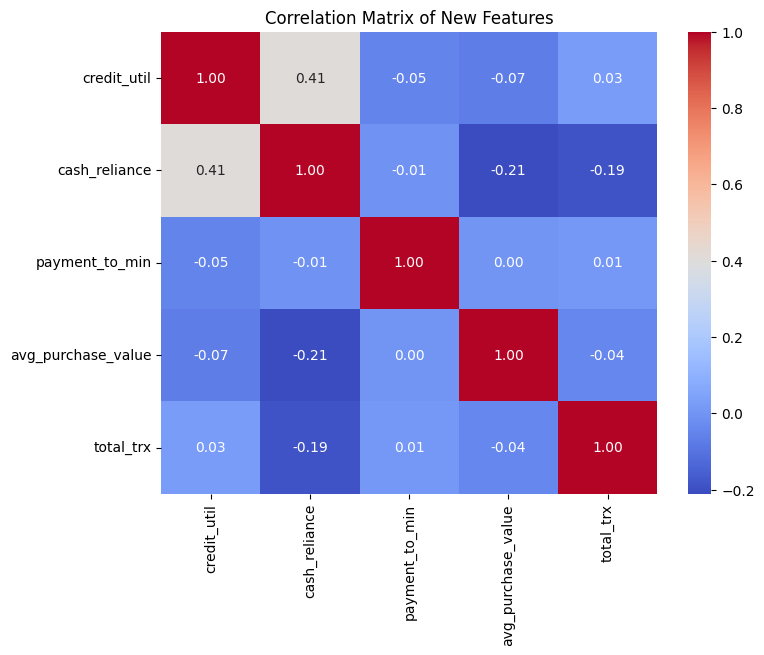

In [ ]:


enhanced_cc['credit_util'] = enhanced_cc['BALANCE'] / enhanced_cc['CREDIT_LIMIT']
enhanced_cc['cash_reliance'] = (enhanced_cc['CASH_ADVANCE'] / (enhanced_cc['PURCHASES'] + enhanced_cc['CASH_ADVANCE'])).replace([-np.inf,np.inf],np.nan).fillna(0)
enhanced_cc['payment_to_min'] = (enhanced_cc['PAYMENTS'] / enhanced_cc['MINIMUM_PAYMENTS']).replace([-np.inf,np.inf],np.nan).fillna(0)
enhanced_cc['avg_purchase_value'] = (enhanced_cc['PURCHASES'] / enhanced_cc['PURCHASES_TRX']).replace([-np.inf,np.inf],np.nan).fillna(0)
enhanced_cc['total_trx'] = enhanced_cc['PURCHASES_TRX'] + enhanced_cc['CASH_ADVANCE_TRX']


# Select only the newly created columns for correlation calculation
new_features_corr = enhanced_cc[['credit_util', 'cash_reliance', 'payment_to_min', 'avg_purchase_value', 'total_trx']].corr()

print("Correlation Matrix of New Features:")
print(new_features_corr)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(new_features_corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of New Features')
plt.show()

In [ ]:
pca_pipeline.fit(enhanced_cc)
print(f'explained variance ratio for the three dimensions: {pca_pipeline[-1].explained_variance_ratio_}')
print(f'total explained varaince ratio :{pca_pipeline[-1].explained_variance_ratio_.sum()}')

explained variance ratio for the three dimensions: [0.35332833 0.20061597 0.09557718]
total explained varaince ratio :0.6495214889514687


3d animation of the shape of the processed enhanced data

In [ ]:
enhanced_animation=anim_kmeans_clusters_3d(preprocessor.fit_transform(enhanced_cc))
HTML(enhanced_animation.to_jshtml())


##Trying kmeans

1. We run kmean with an arbitrary number of clusters(4) on the unenhanced  dataset
2. We determine the optimal number of clusters (2) using sihoulette score
3. we rerun the kmean pipeline with 2 clusters on the unenhanced dataset and visualize it
4. Then we do the same thing again with enhanced dataset, results are more encouraging.

In [ ]:
from sklearn.cluster import KMeans


kmean_pipeline=Pipeline(
    [
        ('preprocessing',preprocessor),
        ('kmean',KMeans(n_clusters=4,n_init=10,random_state=42))
    ]
)
kmean_pipeline.fit(cc_explore)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('functiontransformer',
                                  FunctionTransformer(func=<ufunc 'log1p'>,
                                                      inverse_func=<ufunc 'expm1'>)),
                                 ('standardscaler', StandardScaler())])),
                ('kmean', KMeans(n_clusters=4, n_init=10, random_state=42))])

/tmp/ipykernel_56523/1469479085.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


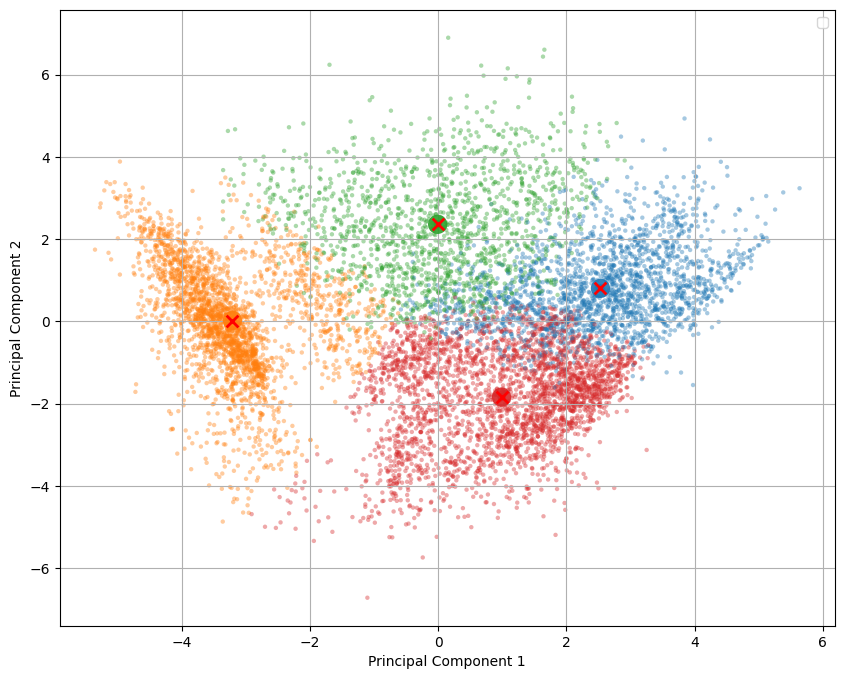

In [ ]:

plot_kmeans_clusters_2d(kmean_pipeline[:-1].transform(cc_explore),kmean_pipeline[-1].labels_,kmean_pipeline[-1].cluster_centers_)

2 seems to be the best value for k confirming our pca visualization from before

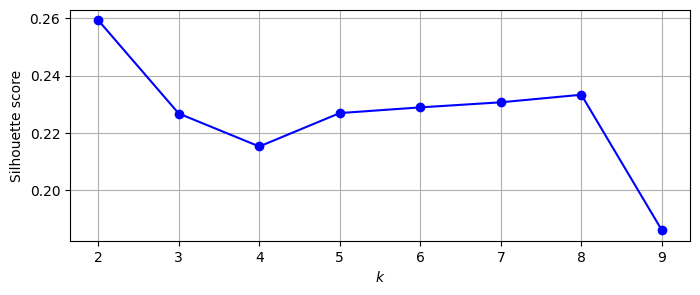

In [ ]:
from sklearn.metrics import silhouette_score
transformed_data=preprocessor.fit_transform(cc_explore)
kmeans_per_k = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(transformed_data)
                for k in range(1, 10)]
silhouette_scores = [silhouette_score(transformed_data, model.labels_)
                     for model in kmeans_per_k[1:]]

plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")

plt.grid()

plt.show()

##visualizaing the two clusters(the unenhanced data version)
**important_point**: I will refer to the clusters as *concentrated* cluster and *diffused* cluster. We cannot use color as our guide because when we rerun the kmean on enhanced data the actual same cluster is assigned different color(because kmean doesnt 'know' the clusters across runs on different data)

1. From what we see from two dimensions it looks like the concentrated  cluster has assimilated a part that should belong to diffused cluster but from three dimension visualization it becomes clear that not only concentrated cluster should assimilate the mentioned part but also extend to another part of the diffused cluster

In [ ]:
kmean_pipeline.set_params(kmean__n_clusters=2)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('functiontransformer',
                                  FunctionTransformer(func=<ufunc 'log1p'>,
                                                      inverse_func=<ufunc 'expm1'>)),
                                 ('standardscaler', StandardScaler())])),
                ('kmean', KMeans(n_clusters=2, n_init=10, random_state=42))])

/tmp/ipykernel_56523/1469479085.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


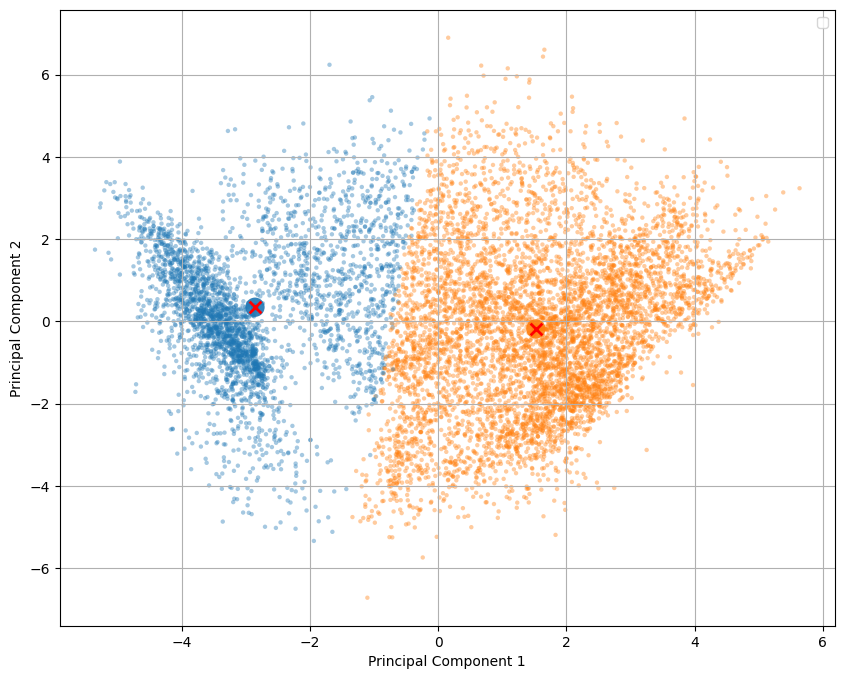

In [ ]:
kmean_pipeline.fit(cc_explore)

plot_kmeans_clusters_2d(kmean_pipeline[:-1].transform(cc_explore),kmean_pipeline[-1].labels_,kmean_pipeline[-1].cluster_centers_)

In [ ]:
animation=anim_kmeans_clusters_3d(kmean_pipeline[:-1].transform(cc_explore),kmean_pipeline[-1].labels_,kmean_pipeline[-1].cluster_centers_)
HTML(animation.to_jshtml())

## Trying with enhanced dataset
now in the 3d plot the light blue cluster takes over the previous blue part that seemed like it should belong to the light blue cluster

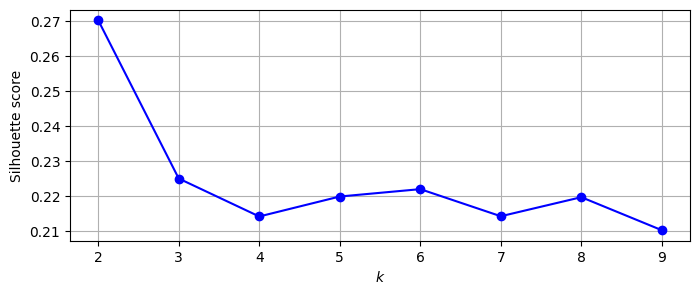

In [ ]:
from sklearn.metrics import silhouette_score
transformed_data=preprocessor.fit_transform(enhanced_cc)
kmeans_per_k = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(transformed_data)
                for k in range(1, 10)]
silhouette_scores = [silhouette_score(transformed_data, model.labels_)
                     for model in kmeans_per_k[1:]]

plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")

plt.grid()

plt.show()

In [ ]:
kmean_pipeline.set_params(kmean__n_clusters=2)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('functiontransformer',
                                  FunctionTransformer(func=<ufunc 'log1p'>,
                                                      inverse_func=<ufunc 'expm1'>)),
                                 ('standardscaler', StandardScaler())])),
                ('kmean', KMeans(n_clusters=2, n_init=10, random_state=42))])

/tmp/ipykernel_56523/1469479085.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


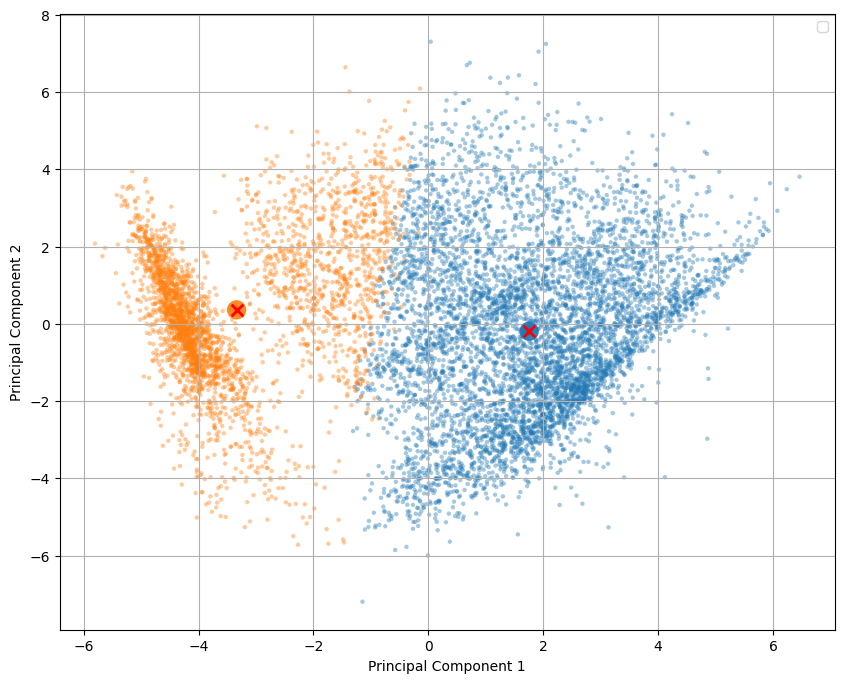

In [ ]:
kmean_pipeline.fit(enhanced_cc)

plot_kmeans_clusters_2d(kmean_pipeline[:-1].transform(enhanced_cc),kmean_pipeline[-1].labels_,kmean_pipeline[-1].cluster_centers_)

In [ ]:
animation=anim_kmeans_clusters_3d(kmean_pipeline[:-1].transform(enhanced_cc),kmean_pipeline[-1].labels_,kmean_pipeline[-1].cluster_centers_)
HTML(animation.to_jshtml())

## Interpreting the clusters
1. We display numerical information of the columns of each group in two parts(because there are a large number of columns)

In [ ]:
cc_evaluate=enhanced_cc.copy()
labels=kmean_pipeline[-1].labels_
cc_evaluate['cluster']=labels
centers_scaled=kmean_pipeline[-1].cluster_centers_
centers=kmean_pipeline[0].inverse_transform(centers_scaled)



adding a new col

In [ ]:
cc_evaluate['payment_balance'] = cc_evaluate['PAYMENTS'] / cc_evaluate['BALANCE'].replace(0, np.nan)

# rows where BALANCE==0 but PAYMENTS>0 => paid off everything => healthiest => cap-high
# rows where BALANCE==0 AND PAYMENTS==0 => inactive => should be 0 (paid nothing, owe nothing)
paid_off = (cc_evaluate['BALANCE'] == 0) & (cc_evaluate['PAYMENTS'] > 0)
inactive = (cc_evaluate['BALANCE'] == 0) & (cc_evaluate['PAYMENTS'] == 0)

cap = cc_evaluate['payment_balance'].quantile(0.99)          # the high-end cap
cc_evaluate.loc[paid_off, 'payment_balance'] = cap            # treat "paid off" as top of range
cc_evaluate.loc[inactive, 'payment_balance'] = 0

In [ ]:
groups=[]
for name ,group in cc_evaluate.groupby('cluster'):
  groups.append(group)


displaying half columns of each group, because otherwise the middle ones are skipped from displaying

In [ ]:
half=cc_evaluate.shape[1]//2
half

12

In [ ]:
groups[0].iloc[:,:half].describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX
count,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000
mean,1128.617954,0.863245,1464.448540,854.417307,610.417423,336.388916,0.694397,0.282000,0.530108,0.049462,1.139230,21.506987
std,1810.093268,0.249569,2493.703087,1971.272815,1059.774935,1290.279307,0.320363,0.331312,0.384614,0.123866,3.746466,28.254495
min,0.000000,0.000000,0.010000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,0.000000
25%,62.321185,0.818182,305.735000,0.000000,59.620000,0.000000,0.416667,0.000000,0.138393,0.000000,0.000000,6.000000
50%,389.371564,1.000000,734.005000,227.985000,300.005000,0.000000,0.833333,0.166667,0.583333,0.000000,0.000000,12.000000
75%,1403.579990,1.000000,1693.522500,992.722500,745.650000,0.000000,1.000000,0.500000,0.916667,0.000000,0.000000,26.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,29282.109150,1.000000,1.000000,1.000000,1.000000,62.000000,358.000000


In [ ]:
groups[1].iloc[:,:half].describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX
count,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000
mean,2394.328214,0.903976,125.015973,93.638452,31.513945,2202.130531,0.101855,0.051012,0.049008,0.298279,7.265412,1.768332
std,2301.090768,0.208137,491.573460,472.659944,130.142607,2705.797901,0.205452,0.120423,0.159142,0.215647,9.161909,4.361117
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,871.897528,0.909091,0.000000,0.000000,0.000000,453.823404,0.000000,0.000000,0.000000,0.142857,2.000000,0.000000
50%,1617.485182,1.000000,0.000000,0.000000,0.000000,1375.799291,0.000000,0.000000,0.000000,0.250000,5.000000,0.000000
75%,3206.320879,1.000000,94.120000,20.675000,0.000000,2936.897959,0.083333,0.083333,0.000000,0.416667,9.000000,1.000000
max,16304.889250,1.000000,22101.780000,22101.780000,1945.950000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,77.000000


In [ ]:
groups[0].iloc[:,half:].describe()

,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,credit_util,cash_reliance,payment_to_min,avg_purchase_value,total_trx,cluster,payment_balance
count,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000,5868.000000,5868.0,5868.000000
mean,4591.028787,1719.309560,811.459023,0.214695,11.625426,0.283306,0.090431,9.704754,95.276844,22.646217,0.0,47.469294
std,3745.275875,2930.866515,2286.082422,0.334470,1.192749,0.332200,0.208384,133.661748,181.772551,29.167313,0.0,1411.816813
min,150.000000,0.000000,0.019163,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
25%,1600.000000,376.720736,153.821732,0.000000,12.000000,0.019305,0.000000,1.072380,32.923307,7.000000,0.0,0.604410
50%,3400.000000,861.498007,211.537467,0.000000,12.000000,0.116101,0.000000,2.838621,55.233889,12.000000,0.0,3.112892
75%,6500.000000,1908.840688,705.566115,0.333333,12.000000,0.465145,0.000000,7.204023,92.425612,28.000000,0.0,10.183691
max,30000.000000,50721.483360,76406.207520,1.000000,12.000000,2.033580,0.974139,6840.528861,5981.666667,358.000000,0.0,79789.487199


In [ ]:
groups[1].iloc[:,half:].describe()


,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,credit_util,cash_reliance,payment_to_min,avg_purchase_value,total_trx,cluster,payment_balance
count,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000,3082.0,3.082000e+03
mean,4310.081509,1759.483770,1181.541324,0.037610,11.311486,0.589899,0.930352,7.736109,33.114243,9.033744,1.0,4.709997e+02
std,3419.500380,2825.926184,2486.372591,0.122096,1.558444,0.411531,0.158965,80.881266,96.915630,11.103778,0.0,2.163888e+04
min,50.000000,0.000000,0.117036,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.000000e+00
25%,1500.000000,394.639055,301.291981,0.000000,12.000000,0.349470,0.939367,0.726917,0.000000,2.000000,1.0,2.408485e-01
50%,3000.000000,845.494045,583.578106,0.000000,12.000000,0.628888,1.000000,1.084719,0.000000,5.000000,1.0,3.675162e-01
75%,6000.000000,1881.586730,1282.282244,0.000000,12.000000,0.866745,1.000000,3.501158,33.997500,12.000000,1.0,1.439494e+00
max,19600.000000,39461.965800,61031.618600,1.000000,12.000000,15.909951,1.000000,2846.533661,1490.000000,144.000000,1.0,1.185884e+06




## The most dominant pattern CASH_ADVANCE

**Insight**
cluster 0 consumers use credit card for purchases transfering money directly to merchants(as the credit card is meant to be used ).Cluster 1 is smaller than Cluster 0. They take  cash in advance a lot and spend it outside of the credit card system . This suggest they are in need of urgent cash to spend on things that cannot be transacted through credit card. Perhaps they have to pay rent or repay other loans. As Advance_cash has an interest from the get go this mean that they are financially stressed and desparate to get liquidity

**Evidence**
The cash_reliance variable offers the most drastic comparison. Since these distributions are right tailed. I have used violin plot and taken the log of distributions so that ranges are visible.Note that if a number is greater than another number after log transforming it is still greater. In all of the features cluster1 IQR goes past the cluster 0's IQR. As cash_reliance is calculated as a proprotion of purchase+cash_advance high cash_reliance automatically means low purchase reliance and vice versa. Statistcal test are also done


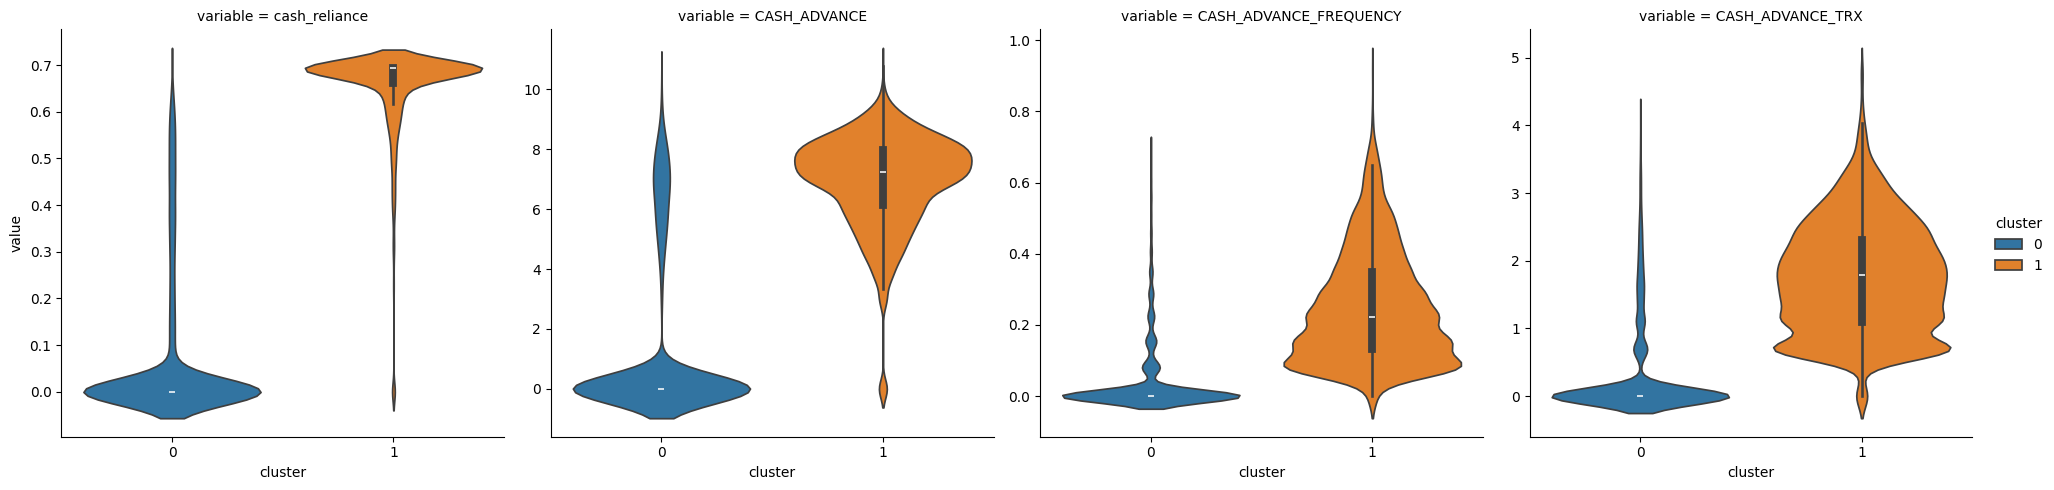

In [ ]:
import seaborn as sns
cash_cols=['cash_reliance','CASH_ADVANCE','CASH_ADVANCE_FREQUENCY','CASH_ADVANCE_TRX']
plot_cash_data = cc_evaluate.melt(
    id_vars='cluster',
    value_vars=cash_cols,
    var_name='variable',
    value_name='value'
)
plot_cash_data['value']=np.log1p(plot_cash_data['value'])
sns.catplot(
    data=plot_cash_data,
    x='cluster',
    y='value',
    col='variable',
    kind='violin',
    hue='cluster',
    sharey=False
)


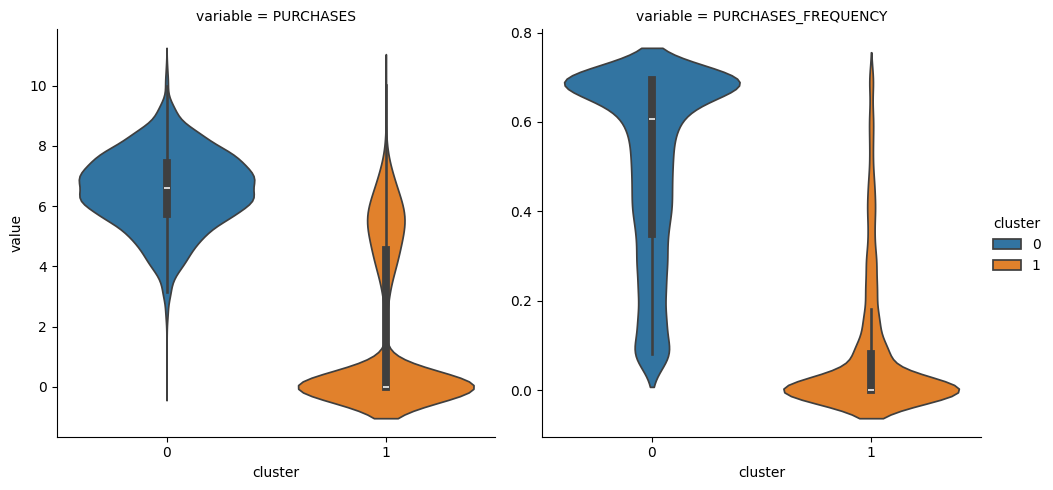

In [ ]:
import seaborn as sns
purchase_cols=['PURCHASES','PURCHASES_FREQUENCY']
plot_purchase_data = cc_evaluate.melt(
    id_vars='cluster',
    value_vars=purchase_cols,
    var_name='variable',
    value_name='value'
)
plot_purchase_data['value']=np.log1p(plot_purchase_data['value'])
sns.catplot(
    data=plot_purchase_data,
    x='cluster',
    y='value',
    col='variable',
    kind='violin',
    hue='cluster',
    sharey=False
)

In [ ]:
from scipy.stats import mannwhitneyu
for col in cash_cols:
    stat, p = mannwhitneyu(groups[0][col], groups[1][col])
    print(f"{col:25s} p={p:.4g}")

cash_reliance             p=0
CASH_ADVANCE              p=0
CASH_ADVANCE_FREQUENCY    p=0
CASH_ADVANCE_TRX          p=0


In [ ]:
from scipy.stats import mannwhitneyu
for col in purchase_cols:
    stat, p = mannwhitneyu(groups[0][col], groups[1][col])
    print(f"{col:25s} p={p:.4g}")

PURCHASES                 p=0
PURCHASES_FREQUENCY       p=0


##Debt
**Insight**
cluster 0 customers have lower debt and have consumed lower proprtion of their credit limit. Cluster 1 customers are closer to their credit limit and have more debt to the bank

**evidence**

credit_limit of both clusters looks the same but when we look at balance(currently owed debt to the bank) and credit_util(proprotion of credit_lmit consumed) the medians of cluster1 are higher than the IQRs of clsuter 0

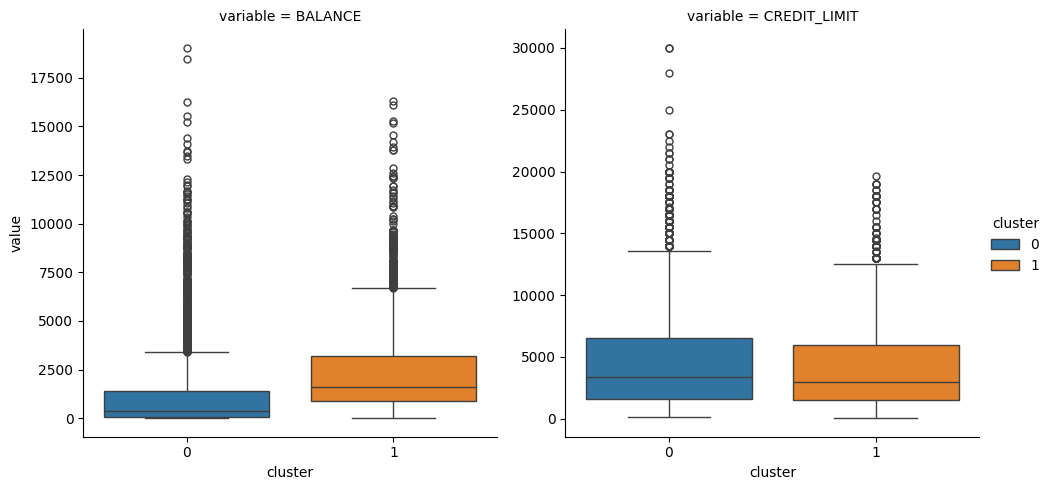

In [ ]:
debt_cols=['BALANCE','CREDIT_LIMIT']
plot_debt_data = cc_evaluate.melt(
    id_vars='cluster',
    value_vars=debt_cols,
    var_name='variable',
    value_name='value'
)

sns.catplot(
    data=plot_debt_data,
    x='cluster',
    y='value',
    col='variable',
    kind='box',
    hue='cluster',


    sharey=False
)

<Axes: xlabel='cluster', ylabel='credit_util'>

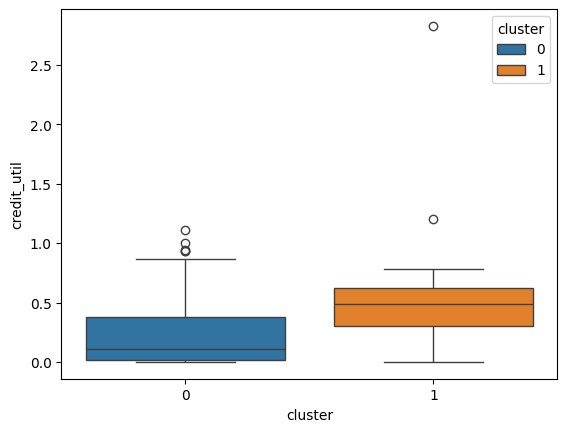

In [ ]:
sns.boxplot(
    x=cc_evaluate['cluster'],
    y=np.log1p(cc_evaluate['credit_util']),
    hue=cc_evaluate['cluster']

)

##BALANCE_FREQUENCY show no difference
both groups inherit the pattern of the overall data set where a significant portion of the clientle are active to the highest degree and customers are thinly  spread among the remining degrees




It also looks like balnce_frequencies are unnaturally cut off at 1.

(0.0, 1.25)

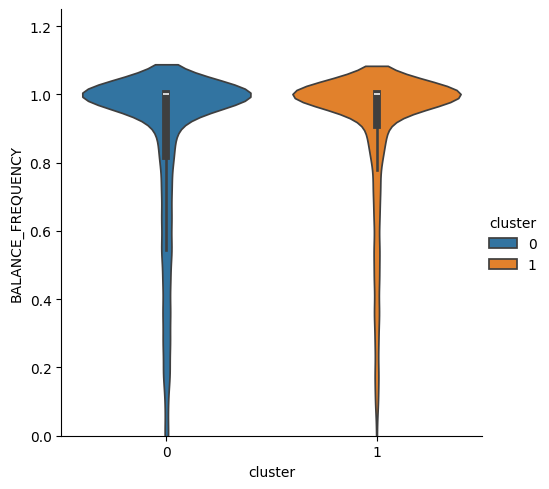

In [ ]:


sns.catplot(
    data=cc_evaluate,
    x='cluster',
    y='BALANCE_FREQUENCY',

    kind='violin',
    hue='cluster',
    sharey=False
)
plt.ylim(0,1.25)

In [ ]:
groups[0]['BALANCE_FREQUENCY'].value_counts(normalize=True)

,proportion
BALANCE_FREQUENCY,
1.000000,0.671779
0.909091,0.050613
0.818182,0.035617
0.545455,0.029652
0.636364,0.028800
0.727273,0.028630
0.454545,0.021643
0.363636,0.021472
0.272727,0.020791


##PAYMENT TO BALANCE Ratio
**Insight**
 cluster 0 have done more payment for one unit of debt they have. If we combine that with the fact that they generally have lower balance(ie debt) this means they payback quickly and dont let balance pile up

On the other hand cluster 1 have smaller ratio, indicating that they let debt pile up

**Evidence**
If we look closely at the plot the median of cluster 1 is below the first quaritle of clsuter 0. Also we have performed a statistical test which confirms our finding



<Axes: xlabel='cluster', ylabel='payment_balance'>

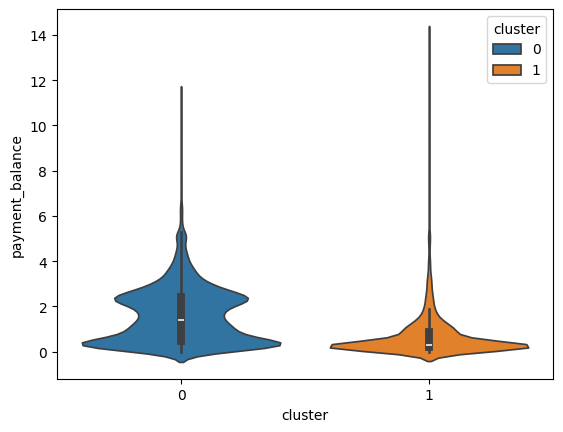

In [ ]:
sns.violinplot(

    x=cc_evaluate['cluster'],
    y=np.log1p(cc_evaluate['payment_balance']),
    hue=cc_evaluate['cluster']
)


In [ ]:
_,p=mannwhitneyu(groups[0]['payment_balance'], groups[1]['payment_balance'])
print(f"payment_balance p={p:.4g}")

payment_balance p=0


## Interpretation of Clusters
###Cluster 0
1. Cluster 0 consists of people who use the credit card  to pay the merchant directly.
2. These people usually have lower debts and dont let the debt pile up.
3. These are reliable healthy coustomer base and they are in the majority

### Cluster 1
1. As a contrast to this there is cluster 1 which consist of people who use the credit card to get cash.
2. They obviously need cash for some transaction that cannot be done through credit card. For example paying rent , informal payments,paying the debt to others. When we draw cash through  credit card interest instantly starts piling up while if we use the credit card for normal payments we get a grace period only after which interest rate come into effect. The fact that customers of clusters0 are drawing cash inspite of this means that they are financially stressed.
3. Moreover they owe more debt to the bank and do not clear their balance quickly. They are the unreliable but profitable(due to interest) customers of the bank.



##Practical recommendation for clusters

###Cluster 0:
The bank should consider to give a credit limit increase to theses customers, because they are reliable. Bank can implement meaures to engage these customers more because as we have seen that about 33% of these customers fall into sparse groups below the maximum balance_frequency. We should increase the engagement of these customers because in this way we would gain regular reliable customers.
Incentives may include;
1. cash backs
2. points(earn points per amount spent).You can later redeem your points
3. Offer of premium cards

### Cluster 1
1. Hold or tighten credit_limit increase because they are unreliable and may default
2. To help them, perhaps offer a lower interest personal loan that is more suitable than cash advance and can help them catch up with their financial mitigation
3. Dont offer rewards or incentives to them because they are less reliable

4. Monitor them overtime and collect data to know how to turn them into a healthy customer.

##  General Recommendations

1.To increase the full payment rate the bank can implement nudges and reminders and show customers how much interest they'll pay and how long it'll take if they pay only the minimum

2. As it stands ONEOFF_PURCHASES form 70% of purchases bank can introduce the option to convert into installments earning money throug interest.

#Insight report
## General Insights
1. 51 percent of people only make purchases and take no cash in advance
2. 22% of people only take cash in advance and not make purchases.
3. 69% of the people use their creditcard to the highest degree of frequency
remaining 31% are thinly spread among lower frequencies and bank can introduce perks to intice the remaining inactive customers

4.  more than 65% of people do not pay full payment ever
5. Portion for One-off purchases is fixed in the purchases of customers(70%)
6. It also looks like that some frequencies  balnce_frequencie are unnaturally cut off at 1.(what is the reason? how was data collected?)

## The most dominant pattern CASH_ADVANCE
cluster 0 consumers use credit card for purchases transfering money directly to merchants(as the credit card is meant to be used ).Cluster 1 is smaller than Cluster 0. They take  cash in advance a lot and spend it outside of the credit card system . This suggest they are in need of urgent cash to spend on things that cannot be transacted through credit card. Perhaps they have to pay rent or repay other loans. As Advance_cash has an interest from the get go this mean that they are financially stressed and desparate to get liquidity



##Debt
cluster 0 customers have lower debt and have consumed lower proprtion of their credit limit. Cluster 1 customers are closer to their credit limit and have more debt to the bank


##PAYMENT TO BALANCE Ratio
cluster 0 have done more payment for one unit of debt they have. If we combine that with the fact that they generally have lower balance(ie debt) this means they payback quickly and dont let balance pile up

On the other hand cluster 1 have smaller ratio, indicating that they let debt pile up

###Cluster 0
1. Cluster 0 consists of people who use the credit card  to pay the merchant directly.
2. These people usually have lower debts and dont let the debt pile up.
3. These are reliable healthy coustomer base and they are in the majority

### Cluster 1
1. As a contrast to this there is cluster 1 which consist of people who use the credit card to get cash.
2. They obviously need cash for some transaction that cannot be done through credit card. For example paying rent , informal payments,paying the debt to others. When we draw cash through  credit card interest instantly starts piling up while if we use the credit card for normal payments we get a grace period only after which interest rate come into effect. The fact that customers of clusters0 are drawing cash inspite of this means that they are financially stressed.
3. Moreover they owe more debt to the bank and do not clear their balance quickly. They are the unreliable but profitable(due to interest) customers of the bank.

##Practical recommendation for clusters

###Cluster 0:
The bank should consider to give a credit limit increase to theses customers, because they are reliable. Bank can implement meaures to engage these customers more because as we have seen that about 33% of these customers fall into sparse groups below the maximum balance_frequency. We should increase the engagement of these customers because in this way we would gain regular reliable customers.
Incentives may include;
1. cash backs
2. points(earn points per amount spent).You can later redeem your points
3. Offer of premium cards

### Cluster 1
1. Hold or tighten credit_limit increase because they are unreliable and may default
2. To help them, perhaps offer a lower interest personal loan that is more suitable than cash advance and can help them catch up with their financial mitigation
3. Dont offer rewards or incentives to them because they are less reliable

4. Monitor them overtime and collect data to know how to turn them into a healthy customer.

##  General Recommendations

1.To increase the full payment rate the bank can implement nudges and reminders and show customers how much interest they'll pay and how long it'll take if they pay only the minimum

2. As it stands ONEOFF_PURCHASES form 70% of purchases bank can introduce the option to convert into installments earning money throug interest.

